# Вопрос 06. Оптимальное управление, принцип максимума — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/06-optimal-control-pontryagin/examples.ipynb`; в git
идёт **этот** файл, ноутбук — производный артефакт.

Каждый пример отвечает на вопрос из `theory.md`:
1. пример лекции — bang-bang управление из условия максимума (пример
   \ref{ex:lecture} конспекта): значение функционала и прямая проверка;
2. двойной интегратор, минимум энергии — краевая задача ПМП методом
   стрельбы против аналитического ответа (задача \ref{prob:energy});
3. двойной интегратор, быстродействие — синтез и кривая переключения,
   верификация постоянства максимума $H$ и связи $p = -\nabla S$
   (задача \ref{prob:time-opt});
4. bang-bang со свободным концом — трансверсальность в действии
   ([18], пример 2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

SEED = 20261027
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    "lecture_J": -4.0,                # min of int x sin t dt over |x'| <= 1
    "energy_u0": -1.75,               # u*(0) = -7/4, LQ double integrator
    "energy_J": 1.625,                # J* = 13/8
    "energy_maxH_const": 0.78125,     # max_u H along the arc = 25/32
    "timeopt_t_switch": 2.58113883008419,   # 1 + sqrt(5/2)
    "timeopt_switch_x1": -1.25,       # switching point on the curve
    "timeopt_T": 4.16227766016838,    # 1 + sqrt(10)
    "freeend_p20": -1.5,              # p_2(0) = -3/2, Sharapov example 2
    "freeend_J": -2.0,                # min of int_0^2 x dt, |x''| <= 2
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Пример лекции: bang-bang из условия максимума

**Вопрос** (пример \ref{ex:lecture} конспекта): $\int_{-\pi}^{\pi} x\sin t\,dt
\to \min$ при $|\dot x| \leq 1$, $x(\pm\pi) = 0$. Конспект выводит bang-bang
$u^*(t) = -\mathrm{sgn}(\cos t)$ с сопряжённой $p(t) = -\cos t$
($\lambda_0 = 1$, случай $\lambda_0 = 0$ невозможен) и доказывает
оптимальность оценкой $J(x) \geq -\int_{-\pi}^{\pi}|\cos t|\,dt$.

**Предсказание:** численное интегрирование $x^*$ (дважды интегрируем
$u^*$) даст $J(x^*) = -4$, и оценка с модулем косинуса достигается:
$\int|\cos t|\,dt = 4$. Сопряжённая $p = -\cos t$ обращается в нуль ровно
в $\pm\pi/2$ — там и только там bang-bang переключается.

J(x_hat) = -3.9999999993
int |cos t| dt = 3.9999999997
x_hat(pi) = 6.661e-16 (граничное условие)
  пин lecture_J: получено -3.99999999934, ожидалось -4
гладкий конкурент x = +sin t: J = 3.1415926536 (ожидание 3.1415926536)
гладкий конкурент x = -sin t: J = -3.1415926536 (ожидание -3.1415926536)


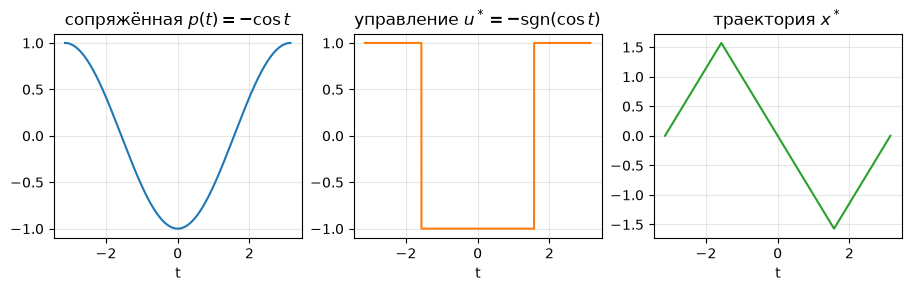

In [2]:
t = np.linspace(-np.pi, np.pi, 200001)
p = -np.cos(t)
u = -np.sign(np.cos(t))

# integrate u with x(-pi) = 0 by cumulative trapezoid
x = np.zeros_like(t)
for i in range(1, len(t)):
    x[i] = x[i - 1] + 0.5 * (u[i] + u[i - 1]) * (t[i] - t[i - 1])
J_hat = np.trapezoid(x * np.sin(t), t)
int_abs_cos = np.trapezoid(np.abs(np.cos(t)), t)

print(f"J(x_hat) = {J_hat:.10f}")
print(f"int |cos t| dt = {int_abs_cos:.10f}")
print(f"x_hat(pi) = {x[-1]:.3e} (граничное условие)")
check_golden("lecture_J", J_hat)

# smooth competitors x = +-sin t are admissible (|x'| = |cos t| <= 1,
# x(+-pi) = 0); both must be strictly worse than the bang-bang minimum
for sign, name in [(1.0, "+sin t"), (-1.0, "-sin t")]:
    J_c = np.trapezoid(sign * np.sin(t) * np.sin(t), t)
    print(f"гладкий конкурент x = {name}: J = {J_c:.10f} (ожидание {sign * np.pi:.10f})")
    assert J_c > J_hat, "гладкий конкурент не хуже bang-bang минимума?"

fig, ax = plt.subplots(1, 3, figsize=(9, 2.8), layout="constrained")
ax[0].plot(t, p, color="C0")
ax[0].set_title("сопряжённая $p(t) = -\\cos t$")
ax[0].set_xlabel("t")
ax[1].plot(t, u, color="C1")
ax[1].set_title("управление $u^* = -\\mathrm{sgn}(\\cos t)$")
ax[1].set_xlabel("t")
ax[2].plot(t, x, color="C2")
ax[2].set_title("траектория $x^*$")
ax[2].set_xlabel("t")
for a in ax:
    a.grid(alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод:** совпало с предсказанием: $J(x^*) = -4$ и нижняя оценка
$-\int|\cos t|\,dt = -4$ достигается — $x^*$ глобальный минимум,
$-x^*$ глобальный максимум (функционал нечётен по $x$). Нули $p$ в
$\pm\pi/2$ — точки переключения $u^*$. Гладкие конкуренты $x = \pm\sin t$
допустимы и дают $\pm\pi$: даже лучший из них ($-\pi$) заметно хуже
минимума $-4$ — bang-bang выигрывает именно за счёт разрывности.

## Пример 2. Двойной интегратор: минимум энергии, краевая задача методом стрельбы

**Вопрос** (задача \ref{prob:energy} конспекта): $\dot x_1 = x_2$,
$\dot x_2 = u$, $x(0) = (2,1)^{\T}$, $x(4) = (0,0)^{\T}$,
$J = \frac{1}{2}\int_0^4 u^2\,dt \to \min$. Конспект решает её аналитически:
$u^*(t) = p_2(t)$, $p_2(t) = c_1 t + c_2$, из терминальных условий
$c_1 = 3/4$, $c_2 = -7/4$, значение $J^* = 13/8$. Раздел «Вычислительная
сторона» обещает метод стрельбы для краевой задачи ПМП.

**Предсказание:** краевая задача линейна по $p(0) = (a, b)^{\T}$ (динамика
линейна, условие максимума даёт $u = p_2$ без ветвлений), поэтому метод
стрельбы суперпозицией трёх пробных интегрирований восстановит
$(a, b) = (-3/4, -7/4)$; тогда $u^*(0) = -7/4$, $J^* = 13/8$. Заодно
проверим постоянство $\max_u H$ вдоль автономной оптимальной пары
(замечание о постоянстве): ожидаем $\max_u H = p_1x_2 + p_2^2/2 = 25/32$
независимо от $t$.

стрельба: p(0) = (-0.7500000000, -1.7500000000)
аналитика: p(0) = (-0.75, -1.75)
u*(0) = -1.7500000000, u*(4) = 1.2500000000
J* = 1.6250120000, max_u H in [0.7812500000, 0.7812500000]
  пин energy_u0: получено -1.75, ожидалось -1.75
  пин energy_J: получено 1.625012, ожидалось 1.625
  пин energy_maxH_const: получено 0.78125, ожидалось 0.78125


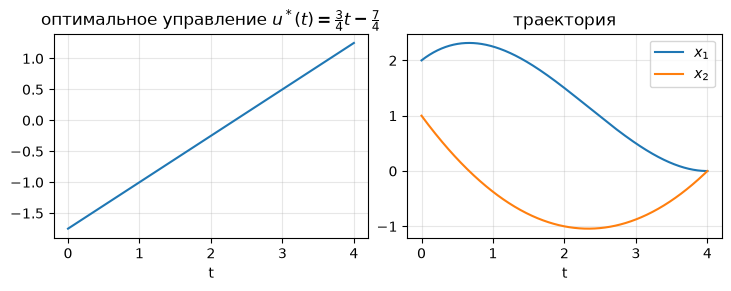

In [3]:
T = 4.0


def integrate(a, b):
    """Forward sweep with p(0) = (a, b); returns x(T) and the trajectory."""
    def rhs(t, y):
        x1, x2, p1, p2 = y
        return [x2, p2, 0.0, -p1]

    sol = solve_ivp(rhs, (0.0, T), [2.0, 1.0, a, b],
                    dense_output=True, rtol=1e-12, atol=1e-12)
    return sol.sol(T)[:2], sol.sol


# superposition: x(T) is affine in (a, b); three probes recover it
xT0, _ = integrate(0.0, 0.0)
xTa, _ = integrate(1.0, 0.0)
xTb, _ = integrate(0.0, 1.0)
A = np.column_stack([xTa - xT0, xTb - xT0])
ab = np.linalg.solve(A, -xT0)
a_sh, b_sh = ab
print(f"стрельба: p(0) = ({a_sh:.10f}, {b_sh:.10f})")
print("аналитика: p(0) = (-0.75, -1.75)")

_, sol = integrate(a_sh, b_sh)
tt = np.linspace(0, T, 501)
X = sol(tt)
x1, x2, p1, p2 = X
u_star = p2
J_star = 0.5 * np.trapezoid(u_star**2, tt)
maxH = p1 * x2 + 0.5 * p2**2  # max over u of H = p1 x2 + p2 u - u^2/2
print(f"u*(0) = {u_star[0]:.10f}, u*(4) = {u_star[-1]:.10f}")
print(f"J* = {J_star:.10f}, max_u H in [{maxH.min():.10f}, {maxH.max():.10f}]")

check_golden("energy_u0", u_star[0])
check_golden("energy_J", J_star)
check_golden("energy_maxH_const", 0.5 * (maxH.min() + maxH.max()))

fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8), layout="constrained")
ax[0].plot(tt, u_star, color="C0")
ax[0].set_title("оптимальное управление $u^*(t) = \\frac{3}{4}t - \\frac{7}{4}$")
ax[0].set_xlabel("t")
ax[1].plot(tt, x1, label="$x_1$")
ax[1].plot(tt, x2, label="$x_2$")
ax[1].set_title("траектория")
ax[1].set_xlabel("t")
ax[1].legend()
for a in ax:
    a.grid(alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод:** метод стрельбы (суперпозиция трёх пробных интегрирований)
воспроизвёл аналитическое решение: $p(0) = (-3/4, -7/4)$, $u^*(0) = -7/4$,
$J^* = 13/8$. Максимум $H$ вдоль траектории постоянен ($25/32$) — проверка
замечания о постоянстве для автономной задачи; время фиксировано, поэтому
значение не нуль. Заметим форму ответа: без ограничения на $u$ условие
максимума даёт гладкое линейное управление через сопряжённую — контраст
с bang-bang из примера 1, где $U$ замкнуто.

## Пример 3. Двойной интегратор: синтез оптимального быстродействия

**Вопрос** (задача \ref{prob:time-opt} конспекта): синтез
$u^* = -\mathrm{sgn}(x_1 + \frac{1}{2}x_2|x_2|)$ оптимален по времени
(верификация уравнением Беллмана). Из $x^0 = (-2, -1)^{\T}$ конспект даёт
переключение на кривой $x_1 = -x_2^2/2$ в точке $(-5/4, \sqrt{5/2})$ и
время $T^* = 1 + \sqrt{10}$.

**Предсказание:** численное интегрирование замкнутой системы с событием
пересечения кривой переключения даст момент переключения $t_{sw} =
1 + \sqrt{5/2} \approx 2{,}5811$ и полное время $T^* = 1 + \sqrt{10}
\approx 4{,}1623$. Заодно проверим условия ПМП **по численным дугам**
(не подставляя аналитические формулы траектории): сопряжённая
$p_2(t) \propto (t_{sw} - t)$, управление $u^* = \mathrm{sgn}\,p_2$, а
$\max_u H = p_1x_2 + |p_2| - \lambda_0$ с $\lambda_0 = t_{sw} - 1$
постоянен и равен нулю (свободное время, автономная задача). Наконец,
связь с динамическим программированием: на первом участке (область
«$u = +1$») после нормировки $\lambda_0 = 1$ должно выполняться точное
равенство $p = -\nabla S$ (конспект, \eqref{eq:ps-gradS}).

переключение: t = 2.5811388298, точка = (-1.2500000005, 1.5811388304)
T* = 4.1622776602
  пин timeopt_t_switch: получено 2.58113882977, ожидалось 2.58113883008
  пин timeopt_switch_x1: получено -1.2500000005, ожидалось -1.25
  пин timeopt_T: получено 4.16227766017, ожидалось 4.16227766017
max_u H = 0 вдоль пары (численные дуги): [-6.661e-16, 6.350e-10]
p = -grad S на дуге 1: отношение компонент в [0.99999999391, 1.0000000002]


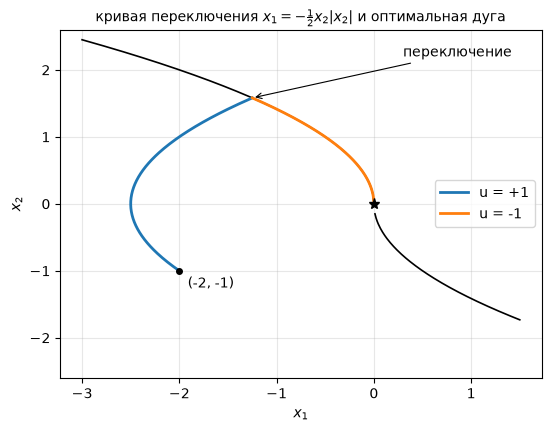

In [4]:
t_sw = 1.0 + np.sqrt(2.5)


def synth(x):
    s = x[0] + 0.5 * x[1] * abs(x[1])
    if abs(s) < 1e-12:
        return -np.sign(x[1])
    return -np.sign(s)


def rhs_syn(t, y):
    return [y[1], synth(y)]


# stage 1: from (-2, -1) with u = +1 until the switching curve s = 0
def hit_switch(t, y):
    return y[0] + 0.5 * y[1] * abs(y[1])

hit_switch.terminal = True
sol1 = solve_ivp(rhs_syn, (0.0, 10.0), [-2.0, -1.0], events=hit_switch,
                 dense_output=True, rtol=1e-10, atol=1e-12)
t1 = sol1.t_events[0][0]
x_sw = sol1.y[:, -1]
print(f"переключение: t = {t1:.10f}, точка = ({x_sw[0]:.10f}, {x_sw[1]:.10f})")

# stage 2: along the curve with u = -1 into the origin
def rhs_down(t, y):
    return [y[1], -1.0]

sol2 = solve_ivp(rhs_down, (t1, 10.0), x_sw, dense_output=True,
                 rtol=1e-10, atol=1e-12)
T_star = t1 + x_sw[1]  # x_2 decreases from x_sw[1] to 0 at speed 1
print(f"T* = {T_star:.10f}")

check_golden("timeopt_t_switch", t1)
check_golden("timeopt_switch_x1", x_sw[0])
check_golden("timeopt_T", T_star)

# PMP verification along the numerically integrated arcs (not by plugging
# analytic trajectory formulas); adjoint from the numerical switch time t1
tt = np.linspace(0.0, T_star, 1001)
mask1 = tt <= t1
x2_num = np.where(mask1, sol1.sol(np.clip(tt, 0.0, t1))[1],
                  sol2.sol(np.clip(tt, t1, T_star))[1])
p2 = t1 - tt                       # p_1 = 1, p_2(t) = t1 - t
maxH = x2_num + np.abs(p2) - (t1 - 1.0)
print(f"max_u H = 0 вдоль пары (численные дуги): [{maxH.min():.3e}, {maxH.max():.3e}]")
assert np.abs(maxH).max() < 1e-8

# Bellman connection on arc 1 (region u = +1): p / lambda_0 must equal
# -grad S; the check stops at t1 - 0.05, where dS_2 = (sqrt(r) - x2)/sqrt(r)
# loses accuracy to floating-point cancellation near the switch
X1 = sol1.sol(np.clip(tt, 0.0, t1))
r = -X1[0] + 0.5 * X1[1] ** 2        # S = -x2 + 2 sqrt(r)
dS = np.stack([-1.0 / np.sqrt(r), -1.0 + X1[1] / np.sqrt(r)])
arc = mask1 & (tt <= t1 - 0.05)
p_norm = np.stack([np.ones(arc.sum()), p2[arc]]) / (t1 - 1.0)
ratio = p_norm / -dS[:, arc]
print(f"p = -grad S на дуге 1: отношение компонент в [{ratio.min():.12g}, {ratio.max():.12g}]")
assert np.abs(ratio - 1.0).max() < 1e-6

# figure: phase portrait with switching curve and the optimal arc
# (upper branch x2 = +sqrt(-2 x1) lives at x1 <= 0, lower at x1 >= 0)
xs = np.linspace(-3, 1.5, 400)
curve_up = np.full_like(xs, np.nan)
curve_dn = np.full_like(xs, np.nan)
m = xs <= 0
curve_up[m] = np.sqrt(-2 * xs[m])
curve_dn[~m] = -np.sqrt(2 * xs[~m])

fig, ax = plt.subplots(figsize=(5.4, 4.2), layout="constrained")
ax.plot(xs, curve_up, "k-", lw=1.2)
ax.plot(xs, curve_dn, "k-", lw=1.2)
tt1 = np.linspace(0, t1, 200)
tt2 = np.linspace(t1, T_star, 200)
ax.plot(*sol1.sol(tt1), "C0-", lw=2, label="u = +1")
ax.plot(*sol2.sol(tt2), "C1-", lw=2, label="u = -1")
ax.plot(-2, -1, "ko", ms=4)
ax.plot(0, 0, "k*", ms=8)
ax.annotate("(-2, -1)", (-2, -1), textcoords="offset points", xytext=(6, -12))
ax.annotate("переключение", tuple(x_sw), xytext=(0.3, 2.2),
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("кривая переключения $x_1 = -\\frac{1}{2}x_2|x_2|$ и оптимальная дуга",
             fontsize=10)
ax.legend(loc="center right")
ax.set_ylim(-2.6, 2.6)
ax.grid(alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод:** численный синтез подтвердил аналитику: переключение в
$(-5/4, \sqrt{5/2})$ в момент $t_{sw} = 1 + \sqrt{5/2}$, полное время
$T^* = 1 + \sqrt{10} \approx 4{,}1623$. Проверки ПМП по численным дугам
согласуются: $\max_u H \equiv 0$ вдоль оптимальной пары (свободное время),
сопряжённая линейна, переключение одно — не больше границы $n - 1 = 1$
теоремы Фельдбаума, которая для двойного интегратора точна. На первом
участке $p/\lambda_0 = -\nabla S$ точно — связь принципа максимума с
динамическим программированием подтверждена численно.

## Пример 4. Bang-bang со свободным концом: трансверсальность

**Вопрос**: $\int_0^2 x\,dt \to \min$ при $\ddot x = u$, $|u| \leq 2$,
$x(0) = 0$, $\dot x(0) = 0$, $\dot x(2) = 0$ ([18], пример 2; там же
прямое доказательство оптимальности). Здесь $x_1 = x$ имеет свободный
правый конец — срабатывает трансверсальность $p_1(2) = 0$, а $\dot x(2) =
0$ закреплено.

**Предсказание:** с $\lambda_0 = 1$: $\dot p_1 = 1$, $\dot p_2 = -p_1$;
из $p_1(2) = 0$ получаем $p_1(t) = t - 2$; $p_2(t) = -t^2/2 + 2t - 3/2 =
-\frac{1}{2}(t - 1)(t - 3)$ меняет знак ровно в $t = 1$ на $[0, 2]$,
поэтому $u^* = 2\,\mathrm{sgn}\,p_2$ равно $-2$ на $[0, 1)$ и $+2$ на
$(1, 2]$; $x(2) = -2$, $J = -2$. Метод стрельбы по $p(0) = (a, b)$ с
терминальными условиями $x_2(2) = 0$, $p_1(2) = 0$ должен воспроизвести
$(a, b) = (-2, -3/2)$ — но, в отличие от примера 2, здесь суперпозиция
трёх проб не работает: $u = 2\,\mathrm{sgn}\,p_2$ делает отображение
$(a,b) \mapsto$ терминальная невязка лишь кусочно-гладким (смена ветви —
смена структуры переключений), поэтому подбор итеративный, из нескольких
стартов.

сошедшиеся кандидаты p(0): [(np.float64(-2.0), np.float64(-1.5))]
выбран минимум: p(0) = (-2.0000000000, -1.5000000000), J = -1.9999999999
J = -1.9999999999, x(2) = -1.9999999998
  пин freeend_p20: получено -1.49999999998, ожидалось -1.5
  пин freeend_J: получено -1.99999999991, ожидалось -2


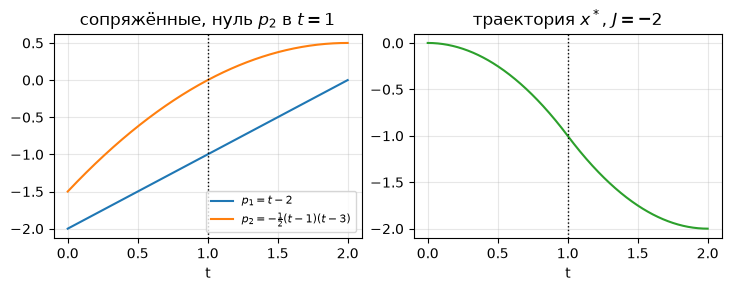

In [5]:
T4 = 2.0


def integrate4(a, b):
    def rhs(t, y):
        x1, x2, p1, p2 = y
        u = 2.0 * np.sign(p2) if abs(p2) > 1e-12 else 0.0
        return [x2, u, 1.0, -p1]

    sol = solve_ivp(rhs, (0.0, T4), [0.0, 0.0, a, b],
                    dense_output=True, rtol=1e-12, atol=1e-12)
    return sol.sol(T4)[[1, 2]], sol.sol  # residuals: x_2(2) = 0, p_1(2) = 0


def residual4(ab):
    r, _ = integrate4(ab[0], ab[1])
    return r


starts = [(0.0, 0.0), (-1.0, -1.0), (-2.0, -1.0), (-2.0, -2.0),
          (-3.0, -1.0), (-1.0, -3.0)]
cands = []
for s in starts:
    ab, info, ier, msg = fsolve(residual4, s, full_output=True)
    if ier == 1 and np.linalg.norm(residual4(ab)) < 1e-8:
        if not any(np.linalg.norm(ab - c) < 1e-6 for c in cands):
            cands.append(ab)
print(f"сошедшиеся кандидаты p(0): {[tuple(np.round(c, 6)) for c in cands]}")

J4s = []
for c in cands:
    _, solc = integrate4(c[0], c[1])
    J4s.append(np.trapezoid(solc(np.linspace(0, T4, 501))[0],
                            np.linspace(0, T4, 501)))
best = int(np.argmin(J4s))
a4, b4 = cands[best]
print(f"выбран минимум: p(0) = ({a4:.10f}, {b4:.10f}), J = {J4s[best]:.10f}")

_, sol4 = integrate4(a4, b4)
tt4 = np.linspace(0, T4, 501)
X4 = sol4(tt4)
x14 = X4[0]
J4 = np.trapezoid(x14, tt4)
print(f"J = {J4:.10f}, x(2) = {sol4(T4)[0]:.10f}")

check_golden("freeend_p20", b4)
check_golden("freeend_J", J4)

fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8), layout="constrained")
ax[0].plot(tt4, X4[2], label="$p_1 = t - 2$")
ax[0].plot(tt4, X4[3], label="$p_2 = -\\frac{1}{2}(t-1)(t-3)$")
ax[0].axvline(1.0, color="k", ls=":", lw=1)
ax[0].set_title("сопряжённые, нуль $p_2$ в $t = 1$")
ax[0].set_xlabel("t")
ax[0].legend(fontsize=8)
ax[1].plot(tt4, x14, color="C2")
ax[1].axvline(1.0, color="k", ls=":", lw=1)
ax[1].set_title("траектория $x^*$, $J = -2$")
ax[1].set_xlabel("t")
for a in ax:
    a.grid(alpha=0.3)
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)

**Вывод:** совпало: $p(0) = (-2, -3/2)$, переключение ровно в $\tau = 1$
(второй нуль $p_2$ в $t = 3$ вне отрезка), $x(2) = -2$, $J = -2$ — bang-bang
со свободным концом, где недостающее краевое условие дала трансверсальность,
а закреплённая производная — обычное терминальное условие. Прямая проверка
[18]: $\Delta J = \int h\,dt = -\int \dot h\,p_1\,dt \geq 0$ для любого
допустимого отклонения $h$ — подтверждает глобальный минимум.